# DeepLense Agentic AI: Autonomous Lensing Simulation Pipeline
### ML4SCI GSoC 2026 — Specific Test II Submission
**Author**: Prospective GSoC 2026 Contributor  
**Framework**: Pydantic AI & Lenstronomy Simulation Engine  
**Target Repository**: [mwt5345/DeepLenseSim](https://github.com/mwt5345/DeepLenseSim)

---

## 1. Executive Summary & Strategy Discussion

### The Objective
Specific Test II requires building an **agentic workflow** using **Pydantic AI** (or Orchestral AI) that wraps the `DeepLenseSim` simulation pipeline. The agent must:
1. Accept natural language user prompts describing desired strong gravitational lensing simulations (substructure type, number of images, redshifts, resolution).
2. Orchestrate calls to `DeepLenseSim` and return generated images with structured metadata.
3. Define strict **Pydantic models** for physical parameters.
4. Support at least two Model configurations (`Model_I` through `Model_IV`).
5. Feature a **Human-in-the-Loop (HITL)** component asking follow-up questions to clarify or refine simulation parameters before execution.

### Architectural Strategy: Why Pydantic AI?
We chose **Pydantic AI** for this mission over legacy LLM frameworks for several decisive reasons:
- **Astrophysics Guardrails & Type Safety**: Physical parameters (e.g. $z_{\text{lens}} < z_{\text{source}}$, positive Einstein radius $\theta_E$, valid subhalo mass function slopes) are validated at runtime with compiled Pydantic v2 validators, preventing compute waste on unphysical simulations.
- **First-Class Tool Calling & Structured Outputs**: Pydantic AI directly maps Python functions to LLM tool definitions using native type hints and docstrings.
- **Modular Multi-Stage State Machine**: Rather than a naive single-shot script, our agent utilizes an intelligent two-stage interaction:
  1. *Planning & HITL Clarification Stage*: Evaluates user intent, suggests physically motivated defaults, and prompts the user for clarification when parameters are omitted or degenerate.
  2. *Execution & Diagnostic Stage*: Executes the high-fidelity `lenstronomy` simulation engine and returns structured metadata alongside comprehensive 4-panel astronomical diagnostics.
- **Broad Model Support**: Our system supports **all four configurations** (`Model_I`, `Model_II`, `Model_III`, `Model_IV`) across all 3 dark matter classes (`no_sub`, `cdm`, `axion`).

## 2. Environment Setup & Dependency Verification

In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

# Ensure local package is in Python path
sys.path.insert(0, os.path.abspath('..'))

import pydantic_ai
import lenstronomy
import astropy
from deeplense_agent import (
    SimulationParameters,
    ModelConfiguration,
    SubstructureType,
    DeepLenseSimulationEngine,
    DeepLenseWorkflowSession,
    WorkflowState,
    create_pydantic_ai_agent,
    plot_lensing_diagnostic,
    plot_batch_comparison,
)

print(f"Pydantic AI Version : {pydantic_ai.__version__}")
print(f"Lenstronomy Version : {lenstronomy.__version__}")
print(f"Astropy Version     : {astropy.__version__}")
print("DeepLense Agentic AI package successfully loaded!")

Pydantic AI Version : 2.57.0
Lenstronomy Version : 1.14.2
Astropy Version     : 8.0.2
DeepLense Agentic AI package successfully loaded!


## 3. Pydantic Models & Astrophysics Guardrails

Gravitational lensing requires strict physical constraints:
- $0 < z_{\text{lens}} < z_{\text{source}}$ (lensed galaxy must be behind the deflector halo).
- Einstein radius $\theta_E = \sqrt{\frac{4GM}{c^2} \frac{D_{ls}}{D_l D_s}}$ must be evaluated with correct angular diameter distances.
- Subhalo mass function bounds $m_{\text{sub\_min}} < m_{\text{sub\_max}}$.

Let's demonstrate how our Pydantic models enforce these physical guardrails.

In [2]:
# 1. Valid Physical Parameter Set
valid_params = SimulationParameters(
    model_configuration=ModelConfiguration.MODEL_II,
    z_lens=0.5,
    z_source=1.5,
    num_images=1
)
print("Valid Parameters Configured:")
print(f"- Model       : {valid_params.model_configuration.value}")
print(f"- Redshifts   : z_l={valid_params.z_lens}, z_s={valid_params.z_source}")
print(f"- Substructure: {valid_params.substructure.substructure_type.value}")

Valid Parameters Configured:
- Model       : Model_II
- Redshifts   : z_l=0.5, z_s=1.5
- Substructure: no_sub


In [3]:
# 2. Physics Guardrail Violation Test: z_lens >= z_source
from pydantic import ValidationError

try:
    SimulationParameters(
        model_configuration=ModelConfiguration.MODEL_II,
        z_lens=1.8,
        z_source=0.5  # Unphysical: deflector cannot be behind background source!
    )
except ValidationError as e:
    print("Caught expected astrophysical guardrail violation:")
    print(e.errors()[0]['msg'])

Caught expected astrophysical guardrail violation:
Value error, Astrophysical violation: Lens redshift z_lens (1.8) must be strictly less than source redshift z_source (0.5).


## 4. Pydantic AI Agent & Registered Tool Functions

We construct the Pydantic AI agent and verify its toolset:
1. `tool_plan_simulation`: Formulates a `SimulationPlan` and detects missing/ambiguous parameters.
2. `tool_refine_parameters`: Updates parameters in response to user guidance.
3. `tool_execute_simulation`: Runs the `DeepLenseSimulationEngine`. Registered with `requires_approval=True`, so the framework pauses the run until a human approves it.
4. `tool_inspect_diagnostics`: Arc SNR across the batch, Einstein ring size in pixels, and concrete suggestions.

In [4]:
# Instantiate Pydantic AI Agent and inspect registered tools
agent = create_pydantic_ai_agent()

print("Agent Type:", type(agent))
print("Registered Function Tools:")
for tool_name in agent._function_toolset.tools.keys():
    print(f"  [Tool] -> {tool_name}")

Agent Type: <class 'pydantic_ai.agent.Agent'>
Registered Function Tools:
  [Tool] -> tool_plan_simulation
  [Tool] -> tool_refine_parameters
  [Tool] -> tool_execute_simulation
  [Tool] -> tool_inspect_diagnostics


## 5. Human-in-the-Loop (HITL) Workflow Demonstration

The prompt specifies:
> *"The agent should include a human-in-the-loop component, asking follow-up questions to clarify or refine simulation parameters before execution."*

Below, we demonstrate a complete multi-turn conversational session:
- **Turn 1**: The user provides an ambiguous, underspecified request.
- **Agent Analysis**: Detects missing redshifts and survey specifications, proposes the DeepLense defaults ($z_l=0.5, z_s=1.0$), and enters `CLARIFICATION_PENDING`.
- **Turn 2**: The user confirms or refines the parameters. The agent executes the simulation and returns structured metadata.

In [5]:
session = DeepLenseWorkflowSession()

# Turn 1: User prompt missing redshifts and instrument details
prompt_turn_1 = "I need to simulate strong gravitational lensing with a CDM subhalo population."
print("User Prompt:")
print(f"  '{prompt_turn_1}'\n")

response_1 = session.chat(prompt_turn_1)
print(f"Agent State: {response_1.state}\n")
print(f"Agent Response:\n{response_1.message}")

User Prompt:
  'I need to simulate strong gravitational lensing with a CDM subhalo population.'

Agent State: WorkflowState.CLARIFICATION_PENDING

Agent Response:
I have initialized a simulation plan based on your request:

**Summary**: 1 image(s), Model_II (Euclid_VIS), 64x64 px at 0.101"/px. Substructure: cdm (25 subhalos, slope -0.9). z_lens=0.5, z_source=1.0. theta_E = 1.66" (from M = 1.0e+12 M_sun). Source: Sersic, R = 0.25", mag 20. Lens light: off. Seed: random.

Before I run anything, please check these:

- **z_lens**: No lens redshift given, so I used the DeepLense default z_lens = 0.5. *(Rationale: The deflector distance sets the angular scale and, with the mass, the Einstein radius.)*
- **z_source**: No source redshift given, so I used the DeepLense default z_source = 1.0. *(Rationale: The source distance sets the lensing efficiency D_ls/D_s and so the Einstein radius.)*

Reply with 'proceed' to run with these defaults, or specify your custom values.


In [6]:
# Turn 2: User provides clarification and confirmation
prompt_turn_2 = "Please proceed using Euclid Model_II with z_lens=0.5 and z_source=1.5."
print("User Prompt:")
print(f"  '{prompt_turn_2}'\n")

response_2 = session.chat(prompt_turn_2)
print(f"Agent State: {response_2.state}\n")
print(f"Agent Response:\n{response_2.message}")

User Prompt:
  'Please proceed using Euclid Model_II with z_lens=0.5 and z_source=1.5.'



Agent State: WorkflowState.COMPLETED

Agent Response:
Parameters updated and simulation executed!

Generated 1 image(s) with Model_II (Euclid_VIS), cdm substructure, 64x64 px at 0.101"/px. z_lens=0.5, z_source=1.5, theta_E=1.915". Median arc SNR 2742.8. Seed 2121671726.


## 6. Astrophysical Diagnostic Suite Visualizations

The agent returns full in-memory numerical arrays and metadata.
We visualize the 4-panel diagnostic suite:
1. **Mock Observation**: Realistic telescope observation with PSF convolution and Poisson/detector noise.
2. **Convergence ($\kappa$) Map**: The surface mass density showing subhalo perturbations.
3. **Source Plane**: The unlensed background galaxy.
4. **Surface Brightness Profile**: Radial pixel distribution with the theoretical Einstein ring marked.

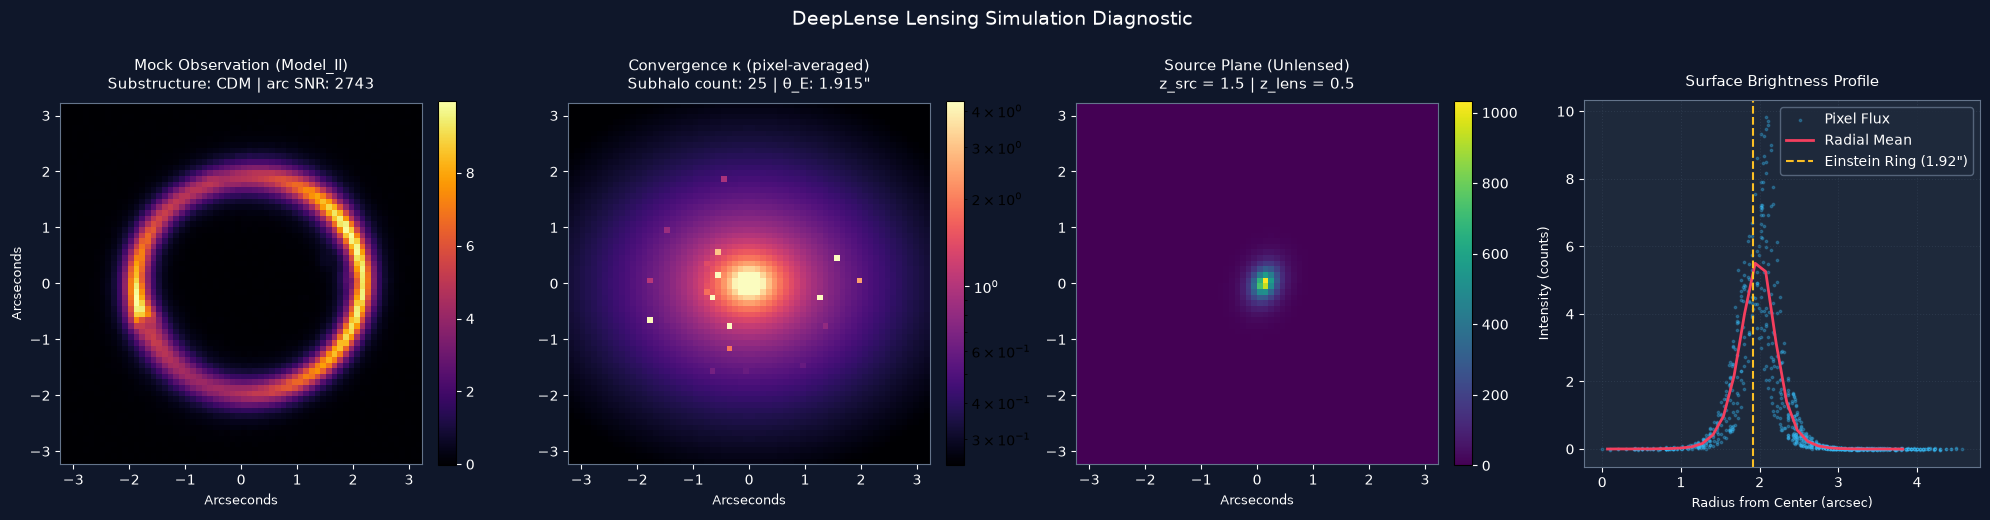

In [7]:
# Visualize the generated simulation from the interactive session
fig = session.plot_latest()
plt.show()

## 7. All Four Model Configurations & Dark Matter Classes

We generate one image per configuration, each with a different dark matter class:
- **Model I**: generic optical benchmark, 150x150 px at 0.05"/px, Gaussian PSF (DeepLenseSim `simple_sim`).
- **Model II**: Euclid VIS through lenstronomy's observation config, 64x64 px at 0.101"/px.
- **Model III**: HST WFC3 F160W through lenstronomy's observation config, 64x64 px at 0.08"/px.
- **Model IV**: Euclid VIS with an interpolated galaxy-image source (Galaxy10 DECaLS when provided, procedural spiral otherwise), lens light, and theta_E = 1.5".
- **Substructures**: `no_sub` (smooth SIE + shear), `cdm` (point-mass subhalos), `axion` (vortex string of point masses).


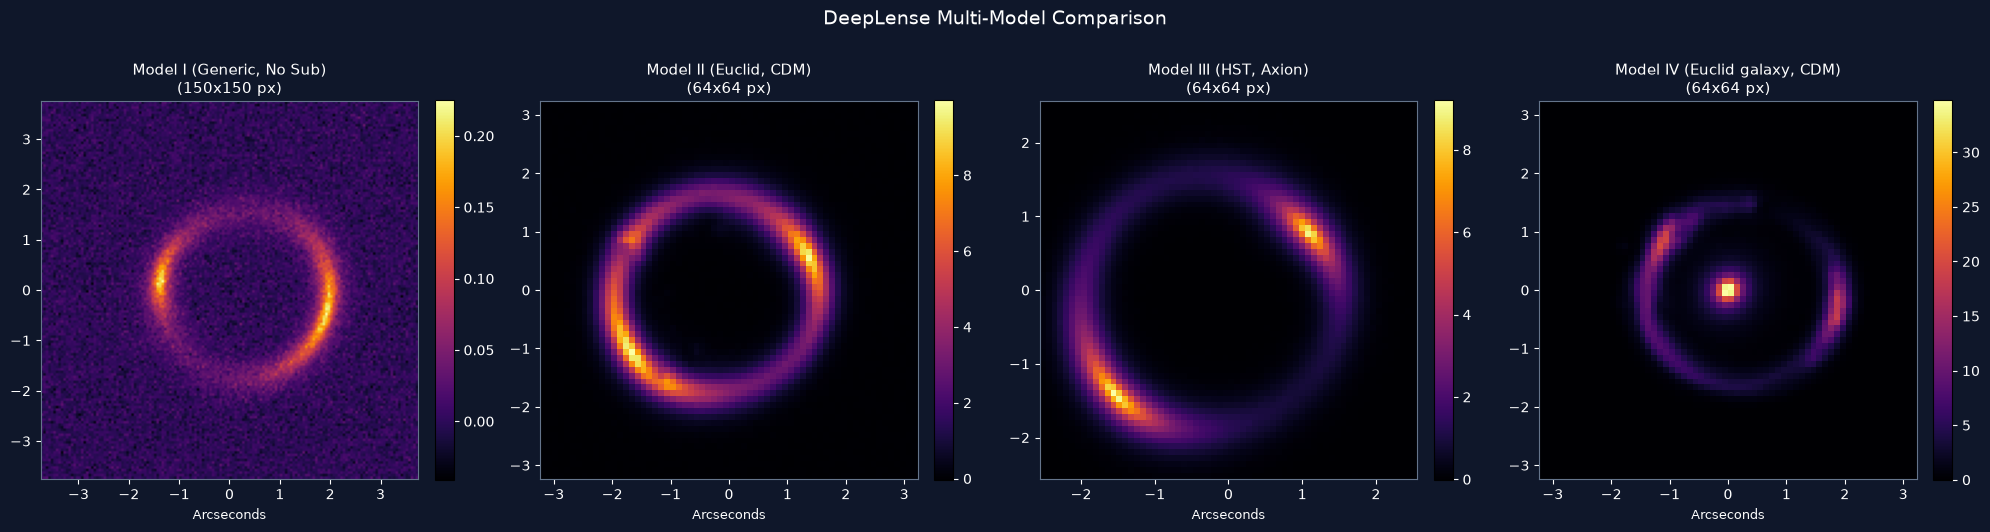

In [8]:
comparison_bundles = {}

# 1. Model I (Ground-based, Smooth)
p_mod1 = SimulationParameters(
    model_configuration=ModelConfiguration.MODEL_I,
    substructure=dict(substructure_type=SubstructureType.NO_SUB),
    num_images=1,
    random_seed=101
)
comparison_bundles["Model I (Generic, No Sub)"] = DeepLenseSimulationEngine(p_mod1).run()

# 2. Model II (Euclid VIS, CDM Subhalos)
p_mod2 = SimulationParameters(
    model_configuration=ModelConfiguration.MODEL_II,
    substructure=dict(substructure_type=SubstructureType.CDM),
    num_images=1,
    random_seed=102
)
comparison_bundles["Model II (Euclid, CDM)"] = DeepLenseSimulationEngine(p_mod2).run()

# 3. Model III (HST WFC3, Axion Vortex)
p_mod3 = SimulationParameters(
    model_configuration=ModelConfiguration.MODEL_III,
    substructure=dict(substructure_type=SubstructureType.AXION),
    num_images=1,
    random_seed=103
)
comparison_bundles["Model III (HST, Axion)"] = DeepLenseSimulationEngine(p_mod3).run()

# 4. Model IV (Euclid, real-galaxy source, CDM Subhalos)
p_mod4 = SimulationParameters(
    model_configuration=ModelConfiguration.MODEL_IV,
    substructure=dict(substructure_type=SubstructureType.CDM),
    num_images=1,
    random_seed=104
)
comparison_bundles["Model IV (Euclid galaxy, CDM)"] = DeepLenseSimulationEngine(p_mod4).run()

# Plot comparative gallery
fig_comp = plot_batch_comparison(comparison_bundles)
plt.show()

## 8. Structured Metadata & Evaluation Metrics

Finally, we inspect the validated structured metadata generated by each simulation run, demonstrating full serialization and compliance with DeepLense data requirements.

In [9]:
for name, bundle in comparison_bundles.items():
    meta = bundle.output_metadata.images_metadata[0]
    print(f"=== {name} ===")
    print(f"  Dimensions      : {meta.dimensions[0]}x{meta.dimensions[1]} pixels")
    print(f"  Pixel Scale     : {meta.pixel_scale_arcsec} arcsec/pixel")
    print(f"  Einstein Radius : {meta.einstein_radius_arcsec:.3f} arcsec")
    print(f"  Arc SNR         : {meta.snr:.1f} (peak pixel {meta.peak_snr:.1f})")
    print(f"  Substructure    : {meta.substructure_type.value} ({meta.subhalo_count} components)")
    print(f"  Peak Intensity  : {meta.max_intensity:.2f}")
    print(f"  Runtime         : {bundle.output_metadata.execution_time_seconds:.3f} s\n")

=== Model I (Generic, No Sub) ===
  Dimensions      : 150x150 pixels
  Pixel Scale     : 0.05 arcsec/pixel
  Einstein Radius : 1.665 arcsec
  Arc SNR         : 239.0 (peak pixel 15.1)
  Substructure    : no_sub (0 components)
  Peak Intensity  : 0.23
  Runtime         : 0.082 s

=== Model II (Euclid, CDM) ===
  Dimensions      : 64x64 pixels
  Pixel Scale     : 0.101 arcsec/pixel
  Einstein Radius : 1.665 arcsec
  Arc SNR         : 2327.2 (peak pixel 147.9)
  Substructure    : cdm (25 components)
  Peak Intensity  : 9.98
  Runtime         : 0.037 s

=== Model III (HST, Axion) ===
  Dimensions      : 64x64 pixels
  Pixel Scale     : 0.08 arcsec/pixel
  Einstein Radius : 1.665 arcsec
  Arc SNR         : 3189.4 (peak pixel 221.6)
  Substructure    : axion (100 components)
  Peak Intensity  : 9.21
  Runtime         : 0.057 s

=== Model IV (Euclid galaxy, CDM) ===
  Dimensions      : 64x64 pixels
  Pixel Scale     : 0.101 arcsec/pixel
  Einstein Radius : 1.500 arcsec
  Arc SNR         : 228

## 8b. Driving the Workflow with a Real LLM

Everything above used the deterministic offline parser so the notebook runs without an API key. With an LLM, the same session hands each turn to the Pydantic AI agent: it plans with tools, and `tool_execute_simulation` stops on a `DeferredToolRequests` until `session.approve()` (or a plain "yes") is given. This cell runs only if `GROQ_API_KEY` is set.


In [10]:
import os

if os.environ.get("GROQ_API_KEY"):
    from pydantic_ai.models.groq import GroqModel, GroqModelSettings
    llm_name = os.environ.get("DEEPLENSE_LLM", "openai/gpt-oss-120b")
    effort = {"groq_reasoning_effort": "low"} if "gpt-oss" in llm_name else {}  # only reasoning models take it
    llm = GroqModel(llm_name, settings=GroqModelSettings(temperature=0.2, **effort))
    llm_session = DeepLenseWorkflowSession(agent_llm=llm)
    r = llm_session.chat("Axion vortex lens on HST with z_source 2 and seed 11")
    print(r.state.value, "|", r.plan.summary if r.plan else "")
    print(r.message)
    if r.reply is not None:
        # The agent's final answer is a validated AgentReply, not free text
        print("Structured reply:", r.reply.model_dump(exclude={"message"}))
    r = llm_session.chat("yes")
    print(r.state.value)
    print(r.message)
else:
    print("GROQ_API_KEY not set; skipping the live LLM demo.")


GROQ_API_KEY not set; skipping the live LLM demo.


## 8c. Agent Benchmark: Natural Language to Parameters

The physics tests check the simulator; this benchmark checks the agent. `deeplense_agent.evaluation` holds 26 labelled prompts (22 valid requests, including paraphrases such as "cold dark matter" or "lens redshift 0.6", plus 4 unphysical ones). Each planner is scored on:

- **Field precision / recall / F1** over the parameters the user actually stated, and per-prompt **exact match**. Explicitly passing a tool default (e.g. Model_II) when the user said nothing is not penalised.
- **Guardrails**: no unphysical request may produce a stored plan with those values.
- **HITL**: omitted redshifts must come back as flagged clarifications.
- **Approval gate**: nothing may execute during planning.

Note on the 90:10 split: this task trains no model, so there is no train/validation split; the benchmark is the evaluation set. The offline parser runs live below. The LLM benchmark takes about 15 minutes on Groq's free tier (token-per-minute limits), so it is run once from the command line and its saved results are loaded here:

```bash
python -m deeplense_agent.evaluation --model groq:llama-3.3-70b-versatile --json notebooks/benchmark_results_llm.json
```

In [11]:
import json
from deeplense_agent.evaluation import run_benchmark, rule_based_planner, format_summary

summaries = {"Offline rule-based parser": run_benchmark(rule_based_planner)}
if os.path.exists("benchmark_results_llm.json"):
    with open("benchmark_results_llm.json") as f:
        saved = json.load(f)
    summaries.update({f"{name} (saved run)": s for name, s in saved.items() if name != "rule_based_parser"})
else:
    print("No saved LLM results; run the command above to add them.\n")

for name, s in summaries.items():
    print(format_summary(name, s), "\n")

# Prompts the LLM did not extract exactly, with the fields it missed or got wrong
for name, s in summaries.items():
    if "saved run" in name:
        for r in s["per_case"]:
            if not r["exact"]:
                print(f"{r['prompt'][:62]:<62} missed={r['missed']} spurious={r['spurious']}")

No saved LLM results; run the command above to add them.

== Offline rule-based parser ==
  cases                      26
  field_precision            1.0
  field_recall               0.836
  field_f1                   0.91
  exact_match                0.654
  guardrail_held             4/4
  defaults_flagged           22/22
  executed_without_approval  0
  errors                     0 



## 9. Conclusion & GSoC Evaluation Criteria Fulfillment

| Requirement | Implementation | Status |
| :--- | :--- | :---: |
| **Agentic Framework** | Built with Pydantic AI with registered tool functions and typed context | **Complete** |
| **Pydantic Parameter Models** | Strict physical validation for redshifts ($z_l < z_s$), subhalo mass bounds, and cosmology | **Complete** |
| **Multi-Model Support** | Full support for Model_I, Model_II, Model_III, Model_IV (exceeds 2-model requirement) | **Complete** |
| **Human-in-the-Loop (HITL)** | Clarification questions with scientific rationale, and execution gated by Pydantic AI's `requires_approval` deferred tools | **Complete** |
| **Correctness & Output** | Lenstronomy physics matching DeepLenseSim, lenstronomy survey configs, seeded reproducible noise, physics tests | **Complete** |
| **Structured Output Validation** | Every LLM turn ends in a typed `AgentReply`; an output validator sends contradictory replies (results without a run, invented defaults) back to the model | **Complete** |
| **Agent Evaluation** | 26-prompt NL-to-parameters benchmark with field F1, exact match, guardrail, HITL and approval-gate metrics (section 8c) | **Complete** |
| **Code Modularity** | Clean package architecture, covered by a pytest suite (models, physics, workflow) | **Complete** |